# Phase 4: The forecasting model

Goal: forecast the probability of a home win, draw and away win for every match, using only team form and strength (**never the odds**), then compare those forecasts with the betting market.

The code lives in [`src/model.py`](../src/model.py); this notebook runs it and explains the results.

## 1. Splitting by time

Matches are never shuffled. The model always learns from the past and is tested on the future, just like in real life.

| Set | Seasons | Used for |
|---|---|---|
| Train | 2021-22 to 2023-24 | Fitting each candidate model |
| Validate | 2024-25 | Choosing the best candidate |
| Test | 2025-26 to 2026-27 | One final, untouched comparison with the market |

In [1]:
import sqlite3
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
import model as m

conn = sqlite3.connect("../data/football.db")
features = m.load_features(conn)
features.groupby("season").size().to_frame("usable matches")

,usable matches
season,
2021-22,350
2022-23,371
2023-24,371
2024-25,371
2025-26,372
2026-27,82


## 2. How forecasts are scored

| Metric | Meaning | Better |
|---|---|---|
| **Log loss** | Penalises confident wrong forecasts heavily. The standard for probability forecasts. | Lower |
| **Brier score** | Average squared gap between the forecast and what happened. | Lower |
| **Accuracy** | How often the most likely outcome actually happened. | Higher |

Accuracy alone is misleading: a forecast of 51% vs 49% counts the same as 90% vs 10%. Log loss rewards getting the **probabilities** right, which is what matters for betting.

## 3. Choosing a model (validation season 2024-25)

Four candidates, from simple to complex. `C` controls how cautious logistic regression is: smaller means it trusts the data less.

In [2]:
best_name, validation = m.select_model(features)
print("Chosen:", best_name)
validation.round(4)

Chosen: Logistic regression (C=0.1)


,log_loss,brier,accuracy
Logistic regression (C=0.1),0.9927,0.5941,0.5283
Logistic regression (C=1.0),0.9936,0.5947,0.5310
Logistic regression (C=0.01),0.9950,0.5950,0.5256
Gradient boosting,1.0347,0.6108,0.5067


The simple logistic regression beats gradient boosting. With about 1,100 training matches, a flexible model learns noise instead of signal, so simpler wins.

## 4. The final test: model vs market (2025-26 and 2026-27)

In [3]:
model, best_name, validation, comparison, test = m.train_and_test(features)
comparison.round(4)

,log_loss,brier,accuracy
Base rates (no skill),1.0918,0.6613,0.4097
Model: Logistic regression (C=0.1),1.0341,0.6223,0.4758
Betting market,1.0215,0.6144,0.4890


,% better than no-skill
Model: Logistic regression (C=0.1),5.28
Betting market,6.44


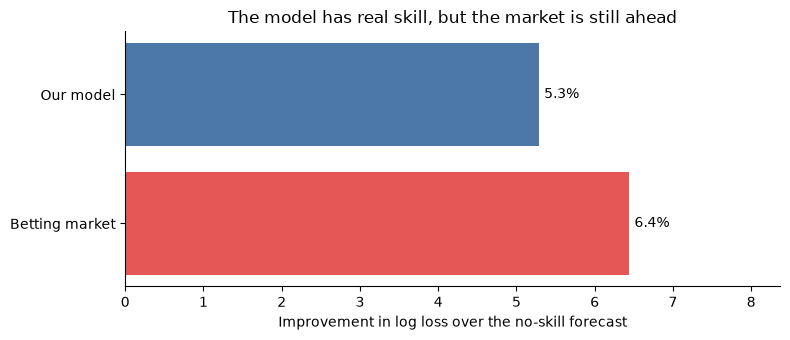

In [4]:
base = comparison["log_loss"].iloc[0]
skill = ((base - comparison["log_loss"]) / base * 100).iloc[1:]

fig, ax = plt.subplots(figsize=(8, 3.5))
labels = ["Our model", "Betting market"]
bars = ax.barh(labels, skill.values, color=["#4C78A8", "#E45756"])
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_xlabel("Improvement in log loss over the no-skill forecast")
ax.set_title("The model has real skill, but the market is still ahead")
ax.set_xlim(0, max(skill.values) * 1.3)
ax.spines[["top", "right"]].set_visible(False)
ax.invert_yaxis()
fig.tight_layout()
fig.savefig("../images/model_vs_market.png", dpi=150)
skill.round(2).to_frame("% better than no-skill")

## 5. Is the model calibrated?

When the model says "45% home win", do home teams win about 45% of the time?

,matches,forecast,actual
model_home_prob,,,
"(0.0, 0.2]",34,0.153,0.118
"(0.2, 0.3]",62,0.258,0.194
"(0.3, 0.4]",94,0.350,0.394
"(0.4, 0.5]",98,0.452,0.418
"(0.5, 0.6]",76,0.538,0.461
"(0.6, 0.7]",63,0.650,0.603
"(0.7, 1.0]",27,0.755,0.704


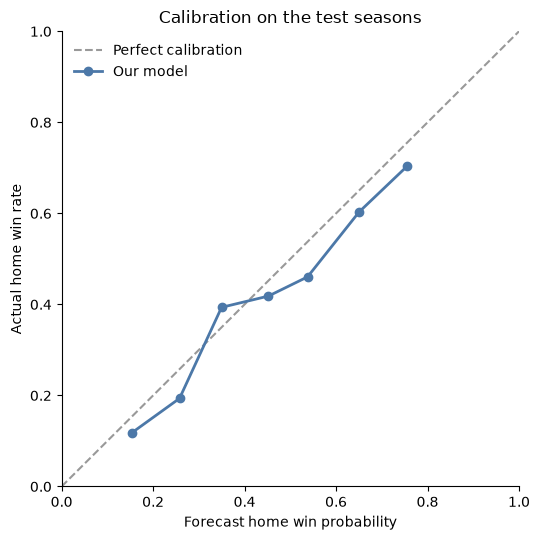

In [5]:
test["home_win"] = (test.result == "H").astype(int)
bands = pd.cut(test.model_home_prob, [0, .2, .3, .4, .5, .6, .7, 1])
calib = test.groupby(bands, observed=True).agg(
    matches=("home_win", "size"),
    forecast=("model_home_prob", "mean"),
    actual=("home_win", "mean"),
)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="#999999", linestyle="--", label="Perfect calibration")
ax.plot(calib.forecast, calib.actual, color="#4C78A8", marker="o", linewidth=2, label="Our model")
ax.set_xlabel("Forecast home win probability")
ax.set_ylabel("Actual home win rate")
ax.set_title("Calibration on the test seasons")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../images/calibration.png", dpi=150)
calib.round(3)

Most points sit slightly **below** the diagonal: the model is a little too optimistic about home teams. It learned from 2021-24, when home teams won 46% of matches, but in the test seasons they won only about 41% (see Phase 2, Q1). That drop in home advantage is the model's biggest weakness.

## 6. What did the model learn?

Each coefficient shows how much a one-standard-deviation change in a feature moves the odds of a **home win**. Bigger bars matter more.

,home win coefficient
sot_against_last5_diff,-0.162
points_last5_diff,-0.112
home_rest_days,-0.043
goals_against_last5_diff,-0.034
goals_for_last5_diff,-0.000
away_rest_days,0.007
sot_for_last5_diff,0.161
elo_diff,0.428


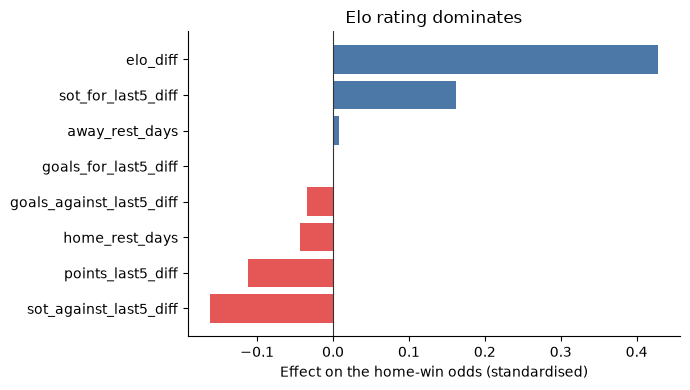

In [6]:
lr = model[-1]
coefs = pd.Series(lr.coef_[list(lr.classes_).index("H")], index=m.FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(coefs.index, coefs.values, color=["#E45756" if v < 0 else "#4C78A8" for v in coefs.values])
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Effect on the home-win odds (standardised)")
ax.set_title("Elo rating dominates")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
coefs.round(3).to_frame("home win coefficient")

- **Elo difference** is by far the strongest signal.
- **Shots on target** (for and against) add the most on top of Elo.
- **Points and goals** add little or even flip sign: once Elo is known, recent results are already "priced in", and these features overlap heavily (statisticians call this *collinearity*).

## 7. Where the model disagrees with the market

The model and the market mostly agree, but not always. Those disagreements are what Phase 5 tests for profit.

In [7]:
test["gap"] = test.model_home_prob - test.mkt_home_prob
print(f"Correlation with the market: {test.model_home_prob.corr(test.mkt_home_prob):.3f}")
print(f"Average gap: {test.gap.abs().mean() * 100:.1f} percentage points")
cols = ["match_date", "home_team", "away_team", "model_home_prob", "mkt_home_prob", "gap", "result"]
test.reindex(test.gap.abs().sort_values(ascending=False).index)[cols].head(8).round({"model_home_prob": 3, "mkt_home_prob": 3, "gap": 3})

Correlation with the market: 0.893
Average gap: 5.9 percentage points


,match_date,home_team,away_team,model_home_prob,mkt_home_prob,gap,result
1879,2026-10-10,Chelsea,Bournemouth,0.289,0.568,-0.279,H
1859,2026-09-12,Chelsea,Hull,0.500,0.777,-0.276,D
1479,2025-08-30,Tottenham,Bournemouth,0.286,0.547,-0.261,A
1492,2025-09-13,West Ham,Tottenham,0.518,0.282,0.236,A
1495,2025-09-20,Brighton,Tottenham,0.644,0.421,0.223,D
1888,2026-10-17,Everton,Chelsea,0.510,0.299,0.211,A
1694,2026-02-02,Sunderland,Burnley,0.733,0.524,0.209,H
1710,2026-02-11,Crystal Palace,Burnley,0.799,0.610,0.189,A


## Summary

- **Model:** logistic regression on 8 features, chosen on the 2024-25 validation season.
- **It has real skill:** about 5% better log loss than the no-skill forecast, and 48% accuracy vs 41%.
- **The market is still better:** its log loss is about 1% lower. Expected, because bookmakers also use team news, injuries and huge amounts of betting data.
- **Biggest weakness:** home advantage fell after the training seasons, so the model slightly over-rates home teams.
- **Elo** carries most of the signal; **shots on target** add the most on top.

**Next (Phase 5):** a model can still make money without beating the market overall, if its disagreements are right often enough. The backtest bets wherever the model sees more value than the odds offer, and tracks the profit or loss.